# Tech Challenge — Detecção de Síndrome dos Ovários Policísticos

Este notebook apresenta o fluxo reproduzível de análise exploratória, pré-processamento, modelagem, avaliação e explicabilidade para apoio à triagem de SOP.

> **Aviso:** projeto acadêmico. O modelo não substitui avaliação ou diagnóstico médico.

In [1]:
%matplotlib inline

from importlib import reload
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import src.train as train_module
reload(train_module)

from src.train import DATA_PATH, TARGET, load_data, main

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
print(f"Alvo: {TARGET}")
print("Variáveis em português: OK")

Alvo: SOP (S/N)
Variáveis em português: OK


## 1. Problema e dados

A tarefa é classificar a presença de SOP (`SOP (S/N)`) usando parâmetros físicos e clínicos de 541 pacientes. As variáveis do dataset original foram traduzidas para português no carregamento. A base foi coletada em dez hospitais de Kerala, Índia, portanto seus resultados não devem ser generalizados sem validação externa.

Caso o arquivo não esteja disponível, execute na raiz do projeto:

```bash
python scripts/download_data.py
```

In [2]:
X, y = load_data(DATA_PATH)
print(f"Registros: {len(X)}")
print(f"Variáveis preditoras: {X.shape[1]}")
print(f"Prevalência de SOP: {y.mean():.1%}")
display(X.head())

Registros: 541
Variáveis preditoras: 41
Prevalência de SOP: 32.7%


,Idade (anos),Peso (kg),Altura (cm),IMC,Grupo sanguíneo,Frequência cardíaca (bpm),Frequência respiratória (rpm),Hemoglobina (g/dL),Ciclo (R/I),Duração do ciclo (dias),Tempo de casamento (anos),Gestante (S/N),Nº de abortos,Beta-HCG I (mIU/mL),Beta-HCG II (mIU/mL),FSH (mIU/mL),LH (mIU/mL),FSH/LH,Quadril (pol),Cintura (pol),Razão cintura/quadril,TSH (mIU/L),AMH (ng/mL),Prolactina (ng/mL),Vitamina D3 (ng/mL),Progesterona (ng/mL),Glicemia aleatória (mg/dL),Ganho de peso (S/N),Crescimento de pelos (S/N),Escurecimento da pele (S/N),Queda de cabelo (S/N),Espinhas (S/N),Fast food (S/N),Exercício regular (S/N),PA sistólica (mmHg),PA diastólica (mmHg),Nº de folículos (E),Nº de folículos (D),Tamanho médio do folículo (E) (mm),Tamanho médio do folículo (D) (mm),Endométrio (mm)
0,28,44.6,152.0,19.300000,15,78,22,10.48,2,5,7.0,0,0,1.99,1.99,7.95,3.68,2.160326,36,30,0.833333,0.68,2.07,45.16,17.1,0.57,92.0,0,0,0,0,0,1.0,0,110,80,3,3,18.0,18.0,8.5
1,36,65.0,161.5,24.921163,15,74,20,11.70,2,5,11.0,1,0,60.80,1.99,6.73,1.09,6.174312,38,32,0.842105,3.16,1.53,20.09,61.3,0.97,92.0,0,0,0,0,0,0.0,0,120,70,3,5,15.0,14.0,3.7
2,33,68.8,165.0,25.270891,11,72,18,11.80,2,5,10.0,1,0,494.08,494.08,5.54,0.88,6.295455,40,36,0.900000,2.54,6.63,10.52,49.7,0.36,84.0,0,0,0,1,1,1.0,0,120,80,13,15,18.0,20.0,10.0
3,37,65.0,148.0,29.674945,13,72,20,12.00,2,5,4.0,0,0,1.99,1.99,8.06,2.36,3.415254,42,36,0.857143,16.41,1.22,36.90,33.4,0.36,76.0,0,0,0,0,0,0.0,0,120,70,2,2,15.0,14.0,7.5
4,25,52.0,161.0,20.060954,11,72,18,10.00,2,5,1.0,1,0,801.45,801.45,3.98,0.90,4.422222,37,30,0.810811,3.57,2.26,30.09,43.8,0.38,84.0,0,0,0,1,0,0.0,0,120,80,3,4,16.0,14.0,7.0


## 2. Análise exploratória

Primeiro avaliamos o balanceamento do alvo, valores ausentes e estatísticas descritivas. A interpretação é tão importante quanto os gráficos: correlação indica associação, não causalidade.

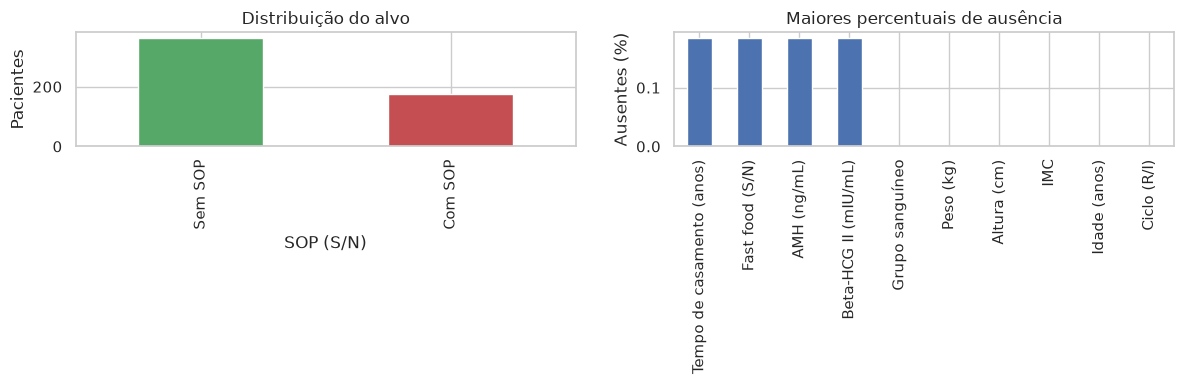

,count,mean,std,min,25%,50%,75%,max
Idade (anos),541.0,31.430684,5.411006,20.000000,28.000000,31.000000,35.000000,48.000000
Peso (kg),541.0,59.637153,11.028287,31.000000,52.000000,59.000000,65.000000,108.000000
Altura (cm),541.0,156.484835,6.033545,137.000000,152.000000,156.000000,160.000000,180.000000
IMC,541.0,24.311285,4.056399,12.417882,21.641274,24.238227,26.634958,38.900000
Grupo sanguíneo,541.0,13.802218,1.840812,11.000000,13.000000,14.000000,15.000000,18.000000
Frequência cardíaca (bpm),541.0,73.247689,4.430285,13.000000,72.000000,72.000000,74.000000,82.000000
Frequência respiratória (rpm),541.0,19.243993,1.688629,16.000000,18.000000,18.000000,20.000000,28.000000
Hemoglobina (g/dL),541.0,11.160037,0.866904,8.500000,10.500000,11.000000,11.700000,14.800000
Ciclo (R/I),541.0,2.560074,0.901950,2.000000,2.000000,2.000000,4.000000,5.000000
Duração do ciclo (dias),541.0,4.940850,1.492020,0.000000,4.000000,5.000000,5.000000,12.000000


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y.map({0: "Sem SOP", 1: "Com SOP"}).value_counts().plot.bar(
    ax=axes[0], color=["#55A868", "#C44E52"], title="Distribuição do alvo"
)
axes[0].set_ylabel("Pacientes")

missing = X.isna().mean().mul(100).sort_values(ascending=False).head(10)
missing.plot.bar(ax=axes[1], color="#4C72B0", title="Maiores percentuais de ausência")
axes[1].set_ylabel("Ausentes (%)")
plt.tight_layout()
plt.show()

display(X.describe().T)

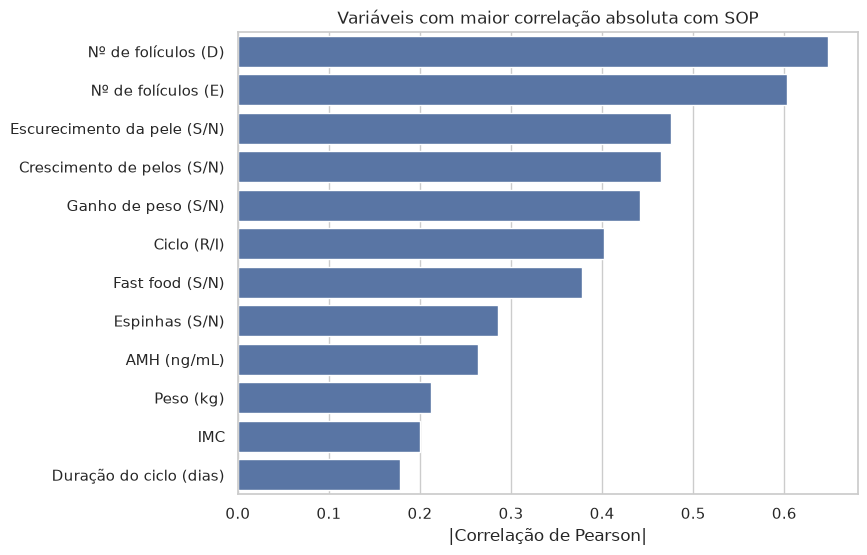

,correlação_com_SOP
Nº de folículos (D),0.648327
Nº de folículos (E),0.603346
Escurecimento da pele (S/N),0.475733
Crescimento de pelos (S/N),0.464667
Ganho de peso (S/N),0.441047
Ciclo (R/I),0.401644
Fast food (S/N),0.377933
Espinhas (S/N),0.286077
AMH (ng/mL),0.263863
Peso (kg),0.211938


In [4]:
correlations = pd.concat([X, y.rename(TARGET)], axis=1).corr(numeric_only=True)
top_correlations = correlations[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).head(12)

plt.figure(figsize=(8, 6))
sns.barplot(x=top_correlations.abs().values, y=top_correlations.index, color="#4C72B0")
plt.title("Variáveis com maior correlação absoluta com SOP")
plt.xlabel("|Correlação de Pearson|")
plt.ylabel("")
plt.show()

top_correlations.to_frame("correlação_com_SOP")

## 3. Pré-processamento e modelagem

O fluxo remove identificadores, converte inconsistências em valores ausentes, imputa numéricos pela mediana, codifica grupo sanguíneo e ciclo com One-Hot Encoding e padroniza os demais atributos.

As transformações ficam dentro do pipeline e são ajustadas somente no treino. Isso evita **data leakage**. Usamos split estratificado 80/20 e validação cruzada com cinco folds. Comparamos:

- **Regressão Logística:** baseline linear e interpretável.
- **Random Forest:** captura relações não lineares e interações.

Os dois modelos usam pesos balanceados.

In [5]:
# Executa treino, validação, avaliação e geração dos artefatos.
main()

             modelo  teste_accuracy  teste_precision  teste_recall  teste_f1  teste_roc_auc  cv_accuracy_media  cv_precision_media  cv_recall_media  cv_f1_media  cv_roc_auc_media
Regressão Logística          0.8716           0.7619        0.8889    0.8205         0.9505             0.8705              0.7723           0.8655       0.8150            0.9290
      Random Forest          0.8991           0.8378        0.8611    0.8493         0.9410             0.8891              0.8208           0.8658       0.8391            0.9565

Melhor modelo: Regressão Logística
Artefatos salvos em data/processed, reports/figures e models.


## 4. Avaliação

Em triagem de saúde, um falso negativo pode atrasar investigação e tratamento. Por isso, priorizamos o **recall da classe com SOP**, sem ignorar precisão, F1, accuracy e ROC-AUC. O melhor modelo é escolhido por recall, seguido de F1 e ROC-AUC.

,modelo,teste_accuracy,teste_precision,teste_recall,teste_f1,teste_roc_auc,cv_accuracy_media,cv_precision_media,cv_recall_media,cv_f1_media,cv_roc_auc_media
0,Regressão Logística,0.872,0.762,0.889,0.821,0.951,0.871,0.772,0.866,0.815,0.929
1,Random Forest,0.899,0.838,0.861,0.849,0.941,0.889,0.821,0.866,0.839,0.956


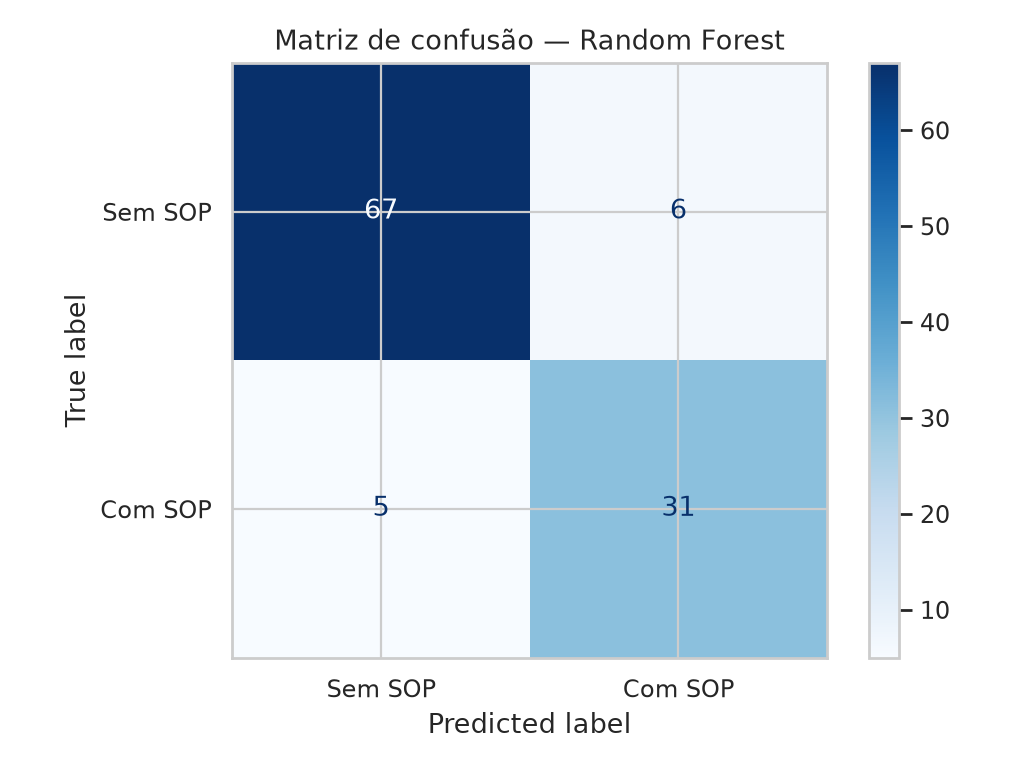

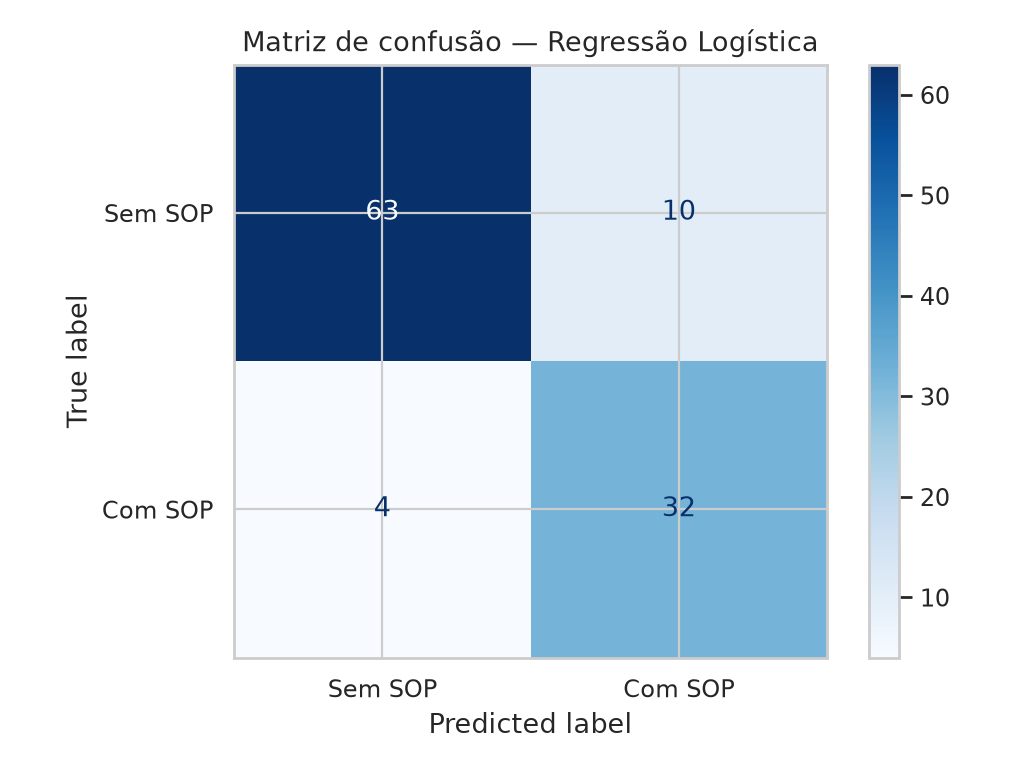

In [6]:
results = pd.read_csv(ROOT / "data/processed/comparacao_modelos.csv")
display(results.style.format(precision=3))

for path in sorted((ROOT / "reports/figures").glob("matriz_confusao_*.png")):
    display(Image(filename=str(path), width=550))

## 5. Explicabilidade

A importância global mostra quais variáveis mais contribuem para a classificação. O SHAP acrescenta direção e intensidade da contribuição. Essas medidas descrevem o comportamento do modelo e **não demonstram causalidade clínica**.

Além do resumo global, analisamos dois casos anônimos do conjunto de teste:
- **Paciente A:** classificação correta
- **Paciente B:** erro de classificação (preferencialmente falso negativo)

Barras à direita aumentam a probabilidade estimada de SOP; barras à esquerda a reduzem.

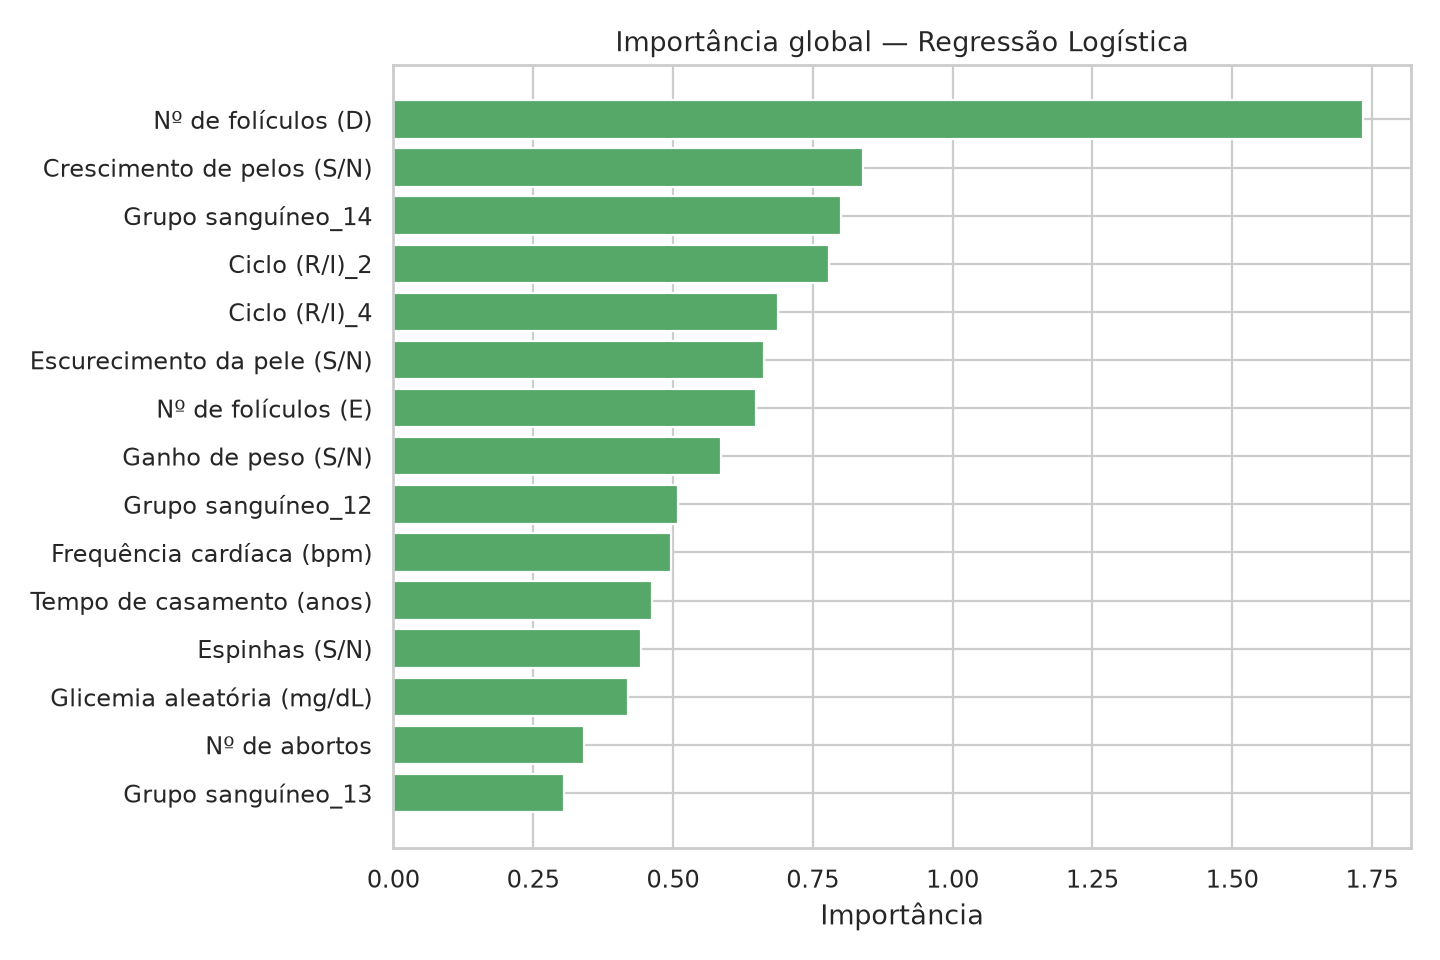

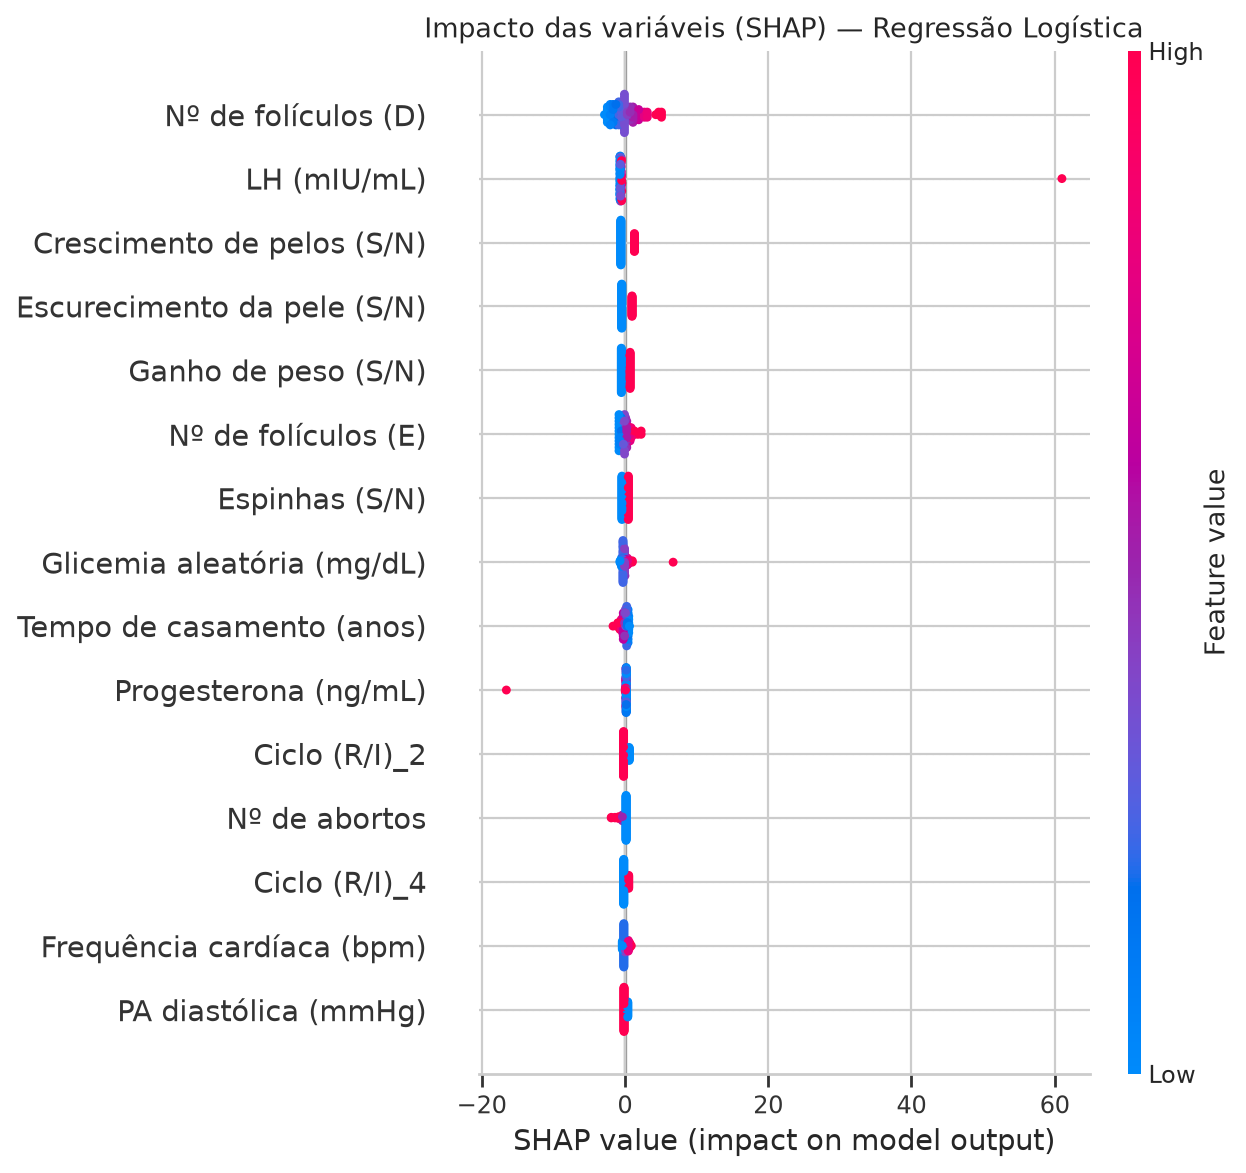

,feature,importance
0,Nº de folículos (D),1.733458
1,Crescimento de pelos (S/N),0.840268
2,Grupo sanguíneo_14,0.799933
3,Ciclo (R/I)_2,0.778351
4,Ciclo (R/I)_4,0.687838
5,Escurecimento da pele (S/N),0.663527
6,Nº de folículos (E),0.648946
7,Ganho de peso (S/N),0.585012
8,Grupo sanguíneo_12,0.508742
9,Frequência cardíaca (bpm),0.495625


,caso,rotulo_anonimo,tipo,descricao,y_real,y_predito,probabilidade_sop,figura
0,acerto,Paciente A,verdadeiro_positivo,Verdadeiro positivo (tem SOP e o modelo acertou),1,1,1.000000,shap_caso_acerto.png
1,erro,Paciente B,falso_negativo,Falso negativo (tem SOP e o modelo errou),1,0,0.005279,shap_caso_erro.png


Paciente A: Verdadeiro positivo (tem SOP e o modelo acertou) | real=1 predito=1 prob=1.000


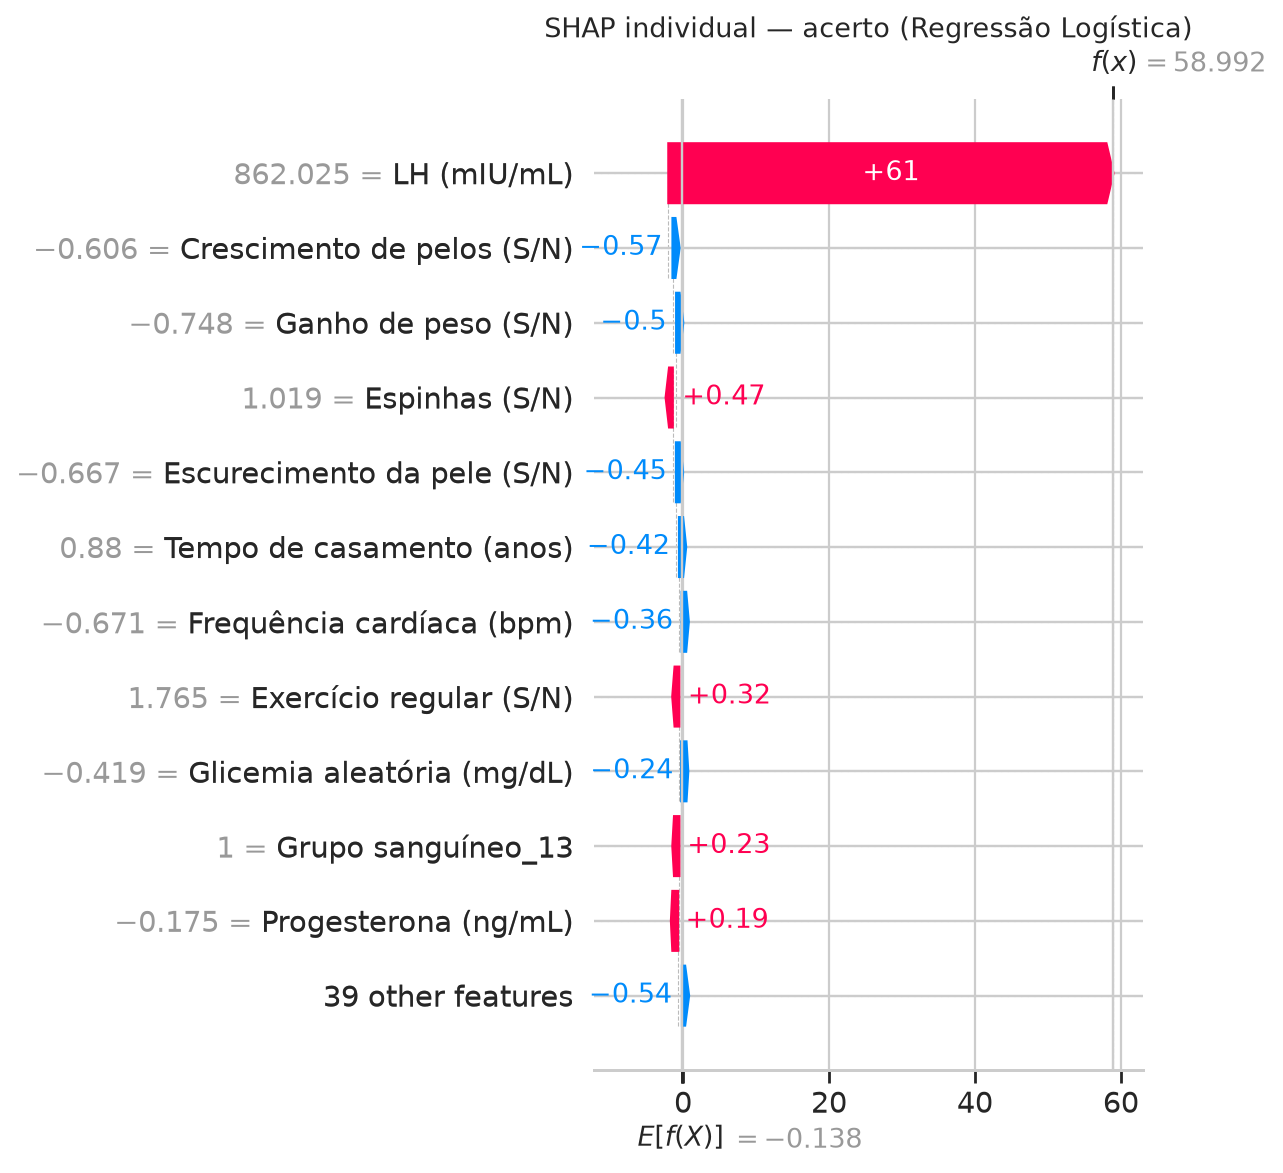

Paciente B: Falso negativo (tem SOP e o modelo errou) | real=1 predito=0 prob=0.005


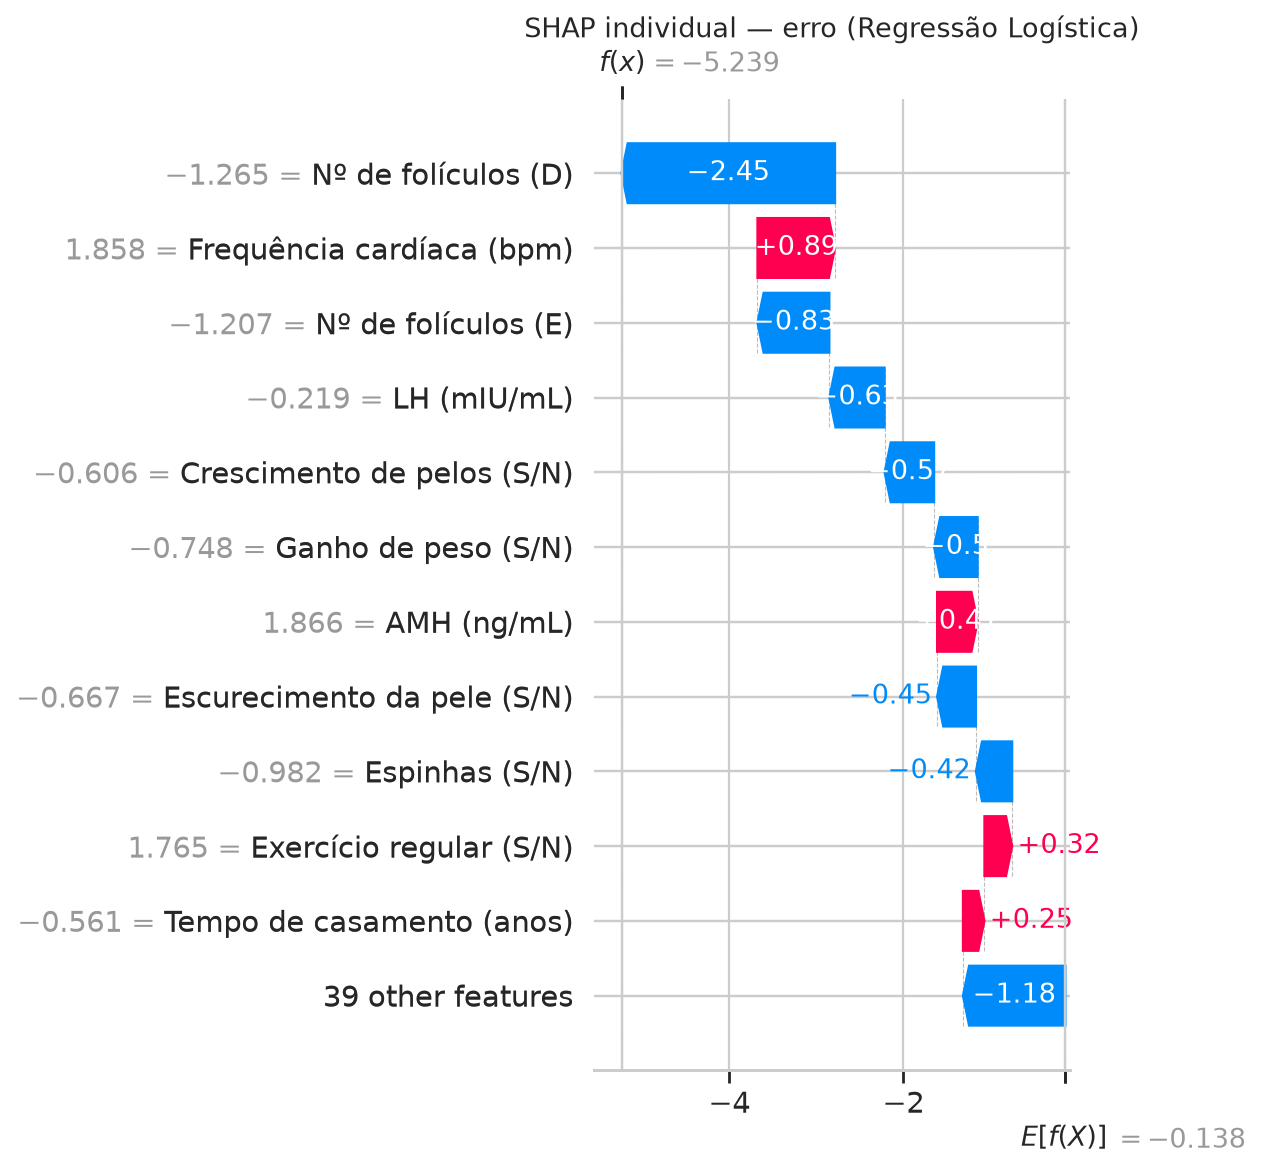

In [7]:
display(Image(filename=str(ROOT / "reports/figures/feature_importance.png"), width=750))
display(Image(filename=str(ROOT / "reports/figures/shap_summary.png"), width=850))

display(pd.read_csv(ROOT / "data/processed/feature_importance.csv").head(15))

casos = pd.read_csv(ROOT / "data/processed/shap_casos.csv")
display(casos)

for _, caso in casos.iterrows():
    print(
        f"{caso['rotulo_anonimo']}: {caso['descricao']} | "
        f"real={caso['y_real']} predito={caso['y_predito']} "
        f"prob={caso['probabilidade_sop']:.3f}"
    )
    display(Image(filename=str(ROOT / "reports/figures" / caso["figura"]), width=850))


## 6. Discussão crítica e conclusão

Os resultados demonstram potencial acadêmico para apoio à triagem, mas não autorizam uso clínico imediato. A amostra é pequena e regional; pode haver mudança de desempenho em outras populações, protocolos e equipamentos.

Antes de uma aplicação real seriam necessários validação externa em dados brasileiros, calibração das probabilidades, definição do limiar com especialistas, avaliação de viés por subgrupo, monitoramento de drift e proteção dos dados segundo a LGPD.

O fluxo recomendado é: **score de risco → priorização → revisão da equipe de saúde**. O médico sempre mantém a decisão final.